# 03. Modelos baseline — contratos de obra (snapshots point-in-time)

Este notebook implementa os modelos baseline usando o dataset cuja conclusão definitiva é a **data de recebimento provisório**.

Objetivos:

1. **Regressão:** estimar `target_dias_atraso`, isto é, quantos dias de atraso haverá na conclusão da obra.
2. **Classificação:** estimar `target_atraso` e sua probabilidade.

Princípios metodológicos adotados:

- usa somente snapshots com `flag_apto_treino = 1`;
- respeita o `split_modelagem` temporal definido no nível do contrato;
- nunca mistura snapshots do mesmo contrato entre treino, validação e teste;
- usa `sample_weight_contrato` para reduzir o excesso de peso de contratos com muitos snapshots;
- exclui identificadores, targets e campos `_controle` das features;
- para **classificação**, a avaliação principal usa apenas snapshots **antes do vencimento do prazo vigente** (`dias_restantes_prazo_vigente >= 0`), pois após o prazo a ocorrência de atraso já é praticamente conhecida;
- reporta métricas apropriadas ao desbalanceamento e à calibração de probabilidades.

> O objetivo é criar referências simples, reproduzíveis e difíceis de “enganar” por leakage. Modelos mais complexos devem ser comparados contra estes resultados.


**Compatibilidade:** se `sample_weight_contrato` e/ou `split_modelagem` não existirem (caso da V1), o notebook os cria automaticamente antes da modelagem.

## Regra de conclusão usada neste notebook

A conclusão oficial do contrato é:

`data_conclusao_definitiva = data_recebimento_provisorio`

Os targets já chegam prontos do notebook 01:

- `target_dias_atraso`
- `target_atraso`

A coluna `data_conclusao_definitiva` é usada apenas para controle, criação do split temporal e validações. Ela **não entra como feature**.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 1. Carregamento e validação do dataset

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

for folder in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Prioriza explicitamente o dataset com conclusão definitiva por recebimento provisório.
candidate_paths = [
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots.csv",
    Path("/mnt/data/dataset_modelagem_obras_snapshots_receb_prov.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots.csv"),
]

DATASET_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATASET_PATH is None:
    raise FileNotFoundError(
        "Nenhum dataset atualizado foi encontrado. Execute primeiro o notebook 01 "
        "com a data de recebimento provisório."
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)

for c in [
    "data_corte",
    "data_os",
    "data_termino_original",
    "data_termino_vigente_corte",
    "data_conclusao_definitiva",
    "data_conclusao_controle",
    "data_conclusao_sistema_controle",
    "data_termino_vigente_final_controle",
]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# ------------------------------------------------------------------
# Validação obrigatória da NOVA definição de target
# ------------------------------------------------------------------
required_base = [
    "id_contrato",
    "data_corte",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "dias_restantes_prazo_vigente",
    "data_conclusao_definitiva",
    "data_termino_vigente_final_controle",
]

missing_base = [c for c in required_base if c not in df.columns]
if missing_base:
    raise ValueError(
        "O dataset encontrado não parece ser a versão baseada em recebimento provisório. "
        f"Colunas obrigatórias ausentes: {missing_base}"
    )

# Compatibilidade: o notebook 01 mantém esse alias.
if "data_conclusao_controle" not in df.columns:
    df["data_conclusao_controle"] = df["data_conclusao_definitiva"]

# Garante que o alias representa a nova definição.
same_date = (
    df["data_conclusao_controle"].fillna(pd.Timestamp("1900-01-01"))
    == df["data_conclusao_definitiva"].fillna(pd.Timestamp("1900-01-01"))
)
if not same_date.all():
    raise ValueError(
        "data_conclusao_controle não coincide com data_conclusao_definitiva. "
        "Verifique se o dataset foi regenerado pelo notebook 01 atualizado."
    )

# Valida target de regressão contra a nova conclusão definitiva.
mask_target = (
    df["data_conclusao_definitiva"].notna()
    & df["data_termino_vigente_final_controle"].notna()
    & df["target_dias_atraso"].notna()
)

target_recalculado = (
    df.loc[mask_target, "data_conclusao_definitiva"]
    - df.loc[mask_target, "data_termino_vigente_final_controle"]
).dt.days.clip(lower=0)

if not np.allclose(
    target_recalculado.astype(float),
    df.loc[mask_target, "target_dias_atraso"].astype(float),
    equal_nan=True,
):
    raise ValueError(
        "target_dias_atraso não está consistente com "
        "data_conclusao_definitiva - data_termino_vigente_final_controle."
    )

# ------------------------------------------------------------------
# Peso por contrato: cria quando ainda não existe
# ------------------------------------------------------------------
if "sample_weight_contrato" not in df.columns:
    counts = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")
        .size()
    )

    df["sample_weight_contrato_raw"] = df["id_contrato"].map(
        lambda cid: 1.0 / counts[cid] if cid in counts.index else np.nan
    )

    mean_w = df.loc[
        df["flag_apto_treino"].eq(1),
        "sample_weight_contrato_raw"
    ].mean()

    df["sample_weight_contrato"] = (
        df["sample_weight_contrato_raw"] / mean_w
    )

    print("Criado automaticamente: sample_weight_contrato")
else:
    print("Usando sample_weight_contrato existente no dataset.")

# ------------------------------------------------------------------
# Split temporal: usa a data de conclusão DEFINITIVA
# ------------------------------------------------------------------
if "split_modelagem" not in df.columns:
    contratos_rotulados = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")["data_conclusao_definitiva"]
        .max()
        .dropna()
        .sort_values()
    )

    n = len(contratos_rotulados)
    n_train = int(np.floor(n * 0.70))
    n_val = int(np.floor(n * 0.15))

    ids_train = set(contratos_rotulados.index[:n_train])
    ids_val = set(contratos_rotulados.index[n_train:n_train + n_val])
    ids_test = set(contratos_rotulados.index[n_train + n_val:])

    df["split_contrato_temporal"] = "scoring"
    df.loc[df["id_contrato"].isin(ids_train), "split_contrato_temporal"] = "train"
    df.loc[df["id_contrato"].isin(ids_val), "split_contrato_temporal"] = "validation"
    df.loc[df["id_contrato"].isin(ids_test), "split_contrato_temporal"] = "test"

    df["split_modelagem"] = np.where(
        df["flag_apto_treino"].eq(1),
        df["split_contrato_temporal"],
        "nao_supervisionado"
    )

    print("Criado automaticamente: split_contrato_temporal")
    print("Criado automaticamente: split_modelagem")
else:
    print("Usando split_modelagem existente no dataset.")

if "split_contrato_temporal" not in df.columns:
    contract_split = (
        df[df["split_modelagem"].isin(["train", "validation", "test"])]
        .drop_duplicates("id_contrato")
        .set_index("id_contrato")["split_modelagem"]
        .to_dict()
    )
    df["split_contrato_temporal"] = (
        df["id_contrato"].map(contract_split).fillna("scoring")
    )

print("\nArquivo:", DATASET_PATH.resolve())
print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())
print(
    "Contratos com conclusão definitiva:",
    df.loc[df["data_conclusao_definitiva"].notna(), "id_contrato"].nunique()
)

display(
    df["split_modelagem"]
    .value_counts(dropna=False)
    .rename("snapshots")
    .to_frame()
)

display(
    df.loc[df["flag_apto_treino"].eq(1)]
    .groupby("split_modelagem")["id_contrato"]
    .nunique()
    .rename("contratos")
    .to_frame()
)


Criado automaticamente: sample_weight_contrato
Criado automaticamente: split_contrato_temporal
Criado automaticamente: split_modelagem

Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Shape: (1657, 49)
Contratos: 78
Contratos com conclusão definitiva: 52


,snapshots
split_modelagem,
nao_supervisionado,992
train,400
test,149
validation,116


,contratos
split_modelagem,
test,9
train,36
validation,7


## 2. Amostras supervisionadas

A regressão usa todos os snapshots rotulados e anteriores à **data de conclusão definitiva (recebimento provisório)**.

A classificação principal usa somente snapshots em que o prazo vigente ainda não venceu (`dias_restantes_prazo_vigente >= 0`). Isso evita um atalho lógico: depois que o prazo vence com a obra ainda não concluída definitivamente, a ocorrência de atraso já é conhecida.


In [3]:
model_data = df[df["flag_apto_treino"].eq(1)].copy()

valid_splits = ["train", "validation", "test"]
model_data = model_data[model_data["split_modelagem"].isin(valid_splits)].copy()

reg_data = model_data.copy()
clf_data = model_data[model_data["dias_restantes_prazo_vigente"].ge(0)].copy()

summary = pd.DataFrame({
    "amostra": ["regressao", "classificacao_pre_prazo"],
    "snapshots": [len(reg_data), len(clf_data)],
    "contratos": [reg_data["id_contrato"].nunique(), clf_data["id_contrato"].nunique()],
    "taxa_atraso": [reg_data["target_atraso"].mean(), clf_data["target_atraso"].mean()],
    "mediana_dias_atraso": [reg_data["target_dias_atraso"].median(), clf_data["target_dias_atraso"].median()],
})
display(summary)

for split in valid_splits:
    r = reg_data[reg_data["split_modelagem"].eq(split)]
    c = clf_data[clf_data["split_modelagem"].eq(split)]
    print(
        f"{split:10s} | regressão: {len(r):4d} snapshots / {r.id_contrato.nunique():2d} contratos"
        f" | classificação pré-prazo: {len(c):4d} / {c.id_contrato.nunique():2d}"
    )

if clf_data["target_atraso"].nunique() < 2:
    raise ValueError("A amostra de classificação não possui as duas classes.")


,amostra,snapshots,contratos,taxa_atraso,mediana_dias_atraso
0,regressao,665,52,0.4767,0.0000
1,classificacao_pre_prazo,574,52,0.4094,0.0000


train      | regressão:  400 snapshots / 36 contratos | classificação pré-prazo:  332 / 36
validation | regressão:  116 snapshots /  7 contratos | classificação pré-prazo:  113 /  7
test       | regressão:  149 snapshots /  9 contratos | classificação pré-prazo:  129 /  9


## 3. Features do baseline

**Não entram:** identificadores, datas finais, status final, targets, pesos, splits e qualquer coluna de controle.

Em particular, ficam fora de `X`:

- `data_conclusao_definitiva`;
- `data_conclusao_controle`;
- `data_conclusao_sistema_controle`;
- `data_termino_vigente_final_controle`.

Essas colunas são usadas apenas para target, split e auditoria.

O fornecedor também fica fora do baseline porque há poucos contratos por fornecedor e o identificador poderia favorecer memorização.


In [4]:
numeric_features = [
    # contrato / prazo
    "valor_total_contrato",
    "prazo_original_dias",
    "dias_desde_os",
    "dias_restantes_prazo_vigente",
    "pct_prazo_consumido",
    "qtd_aditivos_prazo",
    "dias_aditados_acumulados",
    "pct_dias_aditados_sobre_prazo_original",
    "qtd_aditivos_valor",

    # execução / parcelas
    "pct_parcelas_concluidas_vs_previstas",
    "atraso_medio_parcelas_dias",
    "atraso_maximo_parcelas_dias",
    "pct_parcelas_atrasadas",
    "recent_atraso_medio_parcelas_30d",
    "recent_atraso_medio_parcelas_90d",
    "recent_pct_parcelas_atrasadas_90d",
    "delta_atraso_90d_vs_historico",
    "dias_desde_ultima_parcela_concluida",

    # financeiro / liberações
    "pct_financeiro_liberado",
    "gap_prazo_financeiro",
    "recent_atraso_medio_liberacao_90d",
    "dias_desde_ultima_liberacao",

    # gaps e pressão
    "gap_prazo_execucao",
    "pressao_tempo_financeiro",
    "pressao_tempo_execucao",

    # sazonalidade
    "mes_sin",
    "mes_cos",
]

categorical_features = [
    "classificacao_contrato_agrupada",
]

numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]
features = numeric_features + categorical_features

print(f"{len(features)} features selecionadas")
print("Numéricas:", len(numeric_features))
print("Categóricas:", len(categorical_features))


14 features selecionadas
Numéricas: 14
Categóricas: 0


## 4. Preprocessamento

- numéricas: mediana do treino + padronização;
- categóricas: moda + one-hot;
- todo o ajuste ocorre dentro do `Pipeline`, portanto estatísticas do teste não entram no treino.


In [5]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)


# Parte A — Regressão baseline

Comparações:

1. **Dummy mediana:** prevê sempre a mediana ponderada observada no treino.
2. **Ridge:** baseline linear regularizado, mais estável que regressão linear pura diante da multicolinearidade.

Métricas:
- MAE;
- MedAE;
- RMSE;
- R²;
- percentual de previsões com erro absoluto ≤ 30 dias.

O conjunto de **validation** serve para comparação inicial. O **test** permanece como avaliação temporal final.


In [6]:
def split_xy(data, split):
    part = data[data["split_modelagem"].eq(split)].copy()
    X = part[features]
    y_reg = part["target_dias_atraso"].astype(float)
    y_clf = part["target_atraso"].astype(int)
    w = part["sample_weight_contrato"].astype(float)
    return part, X, y_reg, y_clf, w


reg_train, Xr_train, yr_train, _, wr_train = split_xy(reg_data, "train")
reg_val, Xr_val, yr_val, _, wr_val = split_xy(reg_data, "validation")
reg_test, Xr_test, yr_test, _, wr_test = split_xy(reg_data, "test")

regression_models = {
    "dummy_mediana": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "ridge": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", Ridge(alpha=10.0)),
    ]),
}


def regression_metrics(y_true, y_pred, sample_weight=None):
    return {
        "mae": mean_absolute_error(y_true, y_pred, sample_weight=sample_weight),
        "medae": median_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred, sample_weight=sample_weight) ** 0.5,
        "r2": r2_score(y_true, y_pred, sample_weight=sample_weight),
        "pct_erro_ate_30d": np.average(
            np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 30,
            weights=sample_weight,
        ),
        "erro_medio_assinado": np.average(
            np.asarray(y_pred) - np.asarray(y_true),
            weights=sample_weight,
        ),
    }


regression_results = []
fitted_regression = {}

for name, model in regression_models.items():
    model.fit(Xr_train, yr_train, model__sample_weight=wr_train)
    fitted_regression[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xr_val, yr_val, wr_val),
        ("test", Xr_test, yr_test, wr_test),
    ]:
        pred = np.maximum(0, model.predict(X_))
        row = {"modelo": name, "split": split_name}
        row.update(regression_metrics(y_, pred, w_))
        regression_results.append(row)

regression_metrics_df = pd.DataFrame(regression_results).sort_values(["split", "mae"])
display(regression_metrics_df)


,modelo,split,mae,medae,rmse,r2,pct_erro_ate_30d,erro_medio_assinado
1,dummy_mediana,test,36.6667,23.0000,63.0925,-0.5100,0.6667,-36.6667
3,ridge,test,45.9455,46.0210,54.8930,-0.1430,0.3195,8.5701
0,dummy_mediana,validation,12.7143,0.0000,28.8370,-0.2413,0.8571,-12.7143
2,ridge,validation,27.2385,33.4916,36.3803,-0.9757,0.6176,14.5573


In [7]:
# Previsões de regressão no teste
regression_predictions = reg_test[
    ["id_contrato", "data_corte", "faixa_antecedencia", "target_dias_atraso", "sample_weight_contrato"]
].copy()

for name, model in fitted_regression.items():
    regression_predictions[f"pred_{name}"] = np.maximum(0, model.predict(Xr_test))

display(regression_predictions.head(10))


,id_contrato,data_corte,faixa_antecedencia,target_dias_atraso,sample_weight_contrato,pred_dummy_mediana,pred_ridge
1056,217,2023-05-25,>=180d,68.0000,0.3365,0.0000,65.1664
1057,217,2023-05-31,>=180d,68.0000,0.3365,0.0000,66.0698
1058,217,2023-06-30,>=180d,68.0000,0.3365,0.0000,10.0682
1059,217,2023-07-31,>=180d,68.0000,0.3365,0.0000,24.2527
1060,217,2023-08-31,>=180d,68.0000,0.3365,0.0000,31.3930
1061,217,2023-09-30,>=180d,68.0000,0.3365,0.0000,0.0000
1062,217,2023-10-31,>=180d,68.0000,0.3365,0.0000,0.0000
1063,217,2023-11-30,>=180d,68.0000,0.3365,0.0000,0.0000
1064,217,2023-12-31,>=180d,68.0000,0.3365,0.0000,0.0000
1065,217,2024-01-31,>=180d,68.0000,0.3365,0.0000,0.0000


### Desempenho da regressão por antecedência

In [8]:
best_reg_name = (
    regression_metrics_df[regression_metrics_df["split"].eq("validation")]
    .sort_values("mae")
    .iloc[0]["modelo"]
)
best_reg = fitted_regression[best_reg_name]

reg_test_eval = reg_test.copy()
reg_test_eval["pred"] = np.maximum(0, best_reg.predict(Xr_test))
reg_test_eval["erro_abs"] = np.abs(
    reg_test_eval["target_dias_atraso"] - reg_test_eval["pred"]
)

horizon_metrics = (
    reg_test_eval.groupby("faixa_antecedencia", observed=True)
    .apply(lambda g: pd.Series({
        "snapshots": len(g),
        "contratos": g["id_contrato"].nunique(),
        "mae": np.average(g["erro_abs"], weights=g["sample_weight_contrato"]),
        "mediana_erro_abs": g["erro_abs"].median(),
    }))
    .reset_index()
)

display(horizon_metrics)


,faixa_antecedencia,snapshots,contratos,mae,mediana_erro_abs
0,30-89d,27.0000,9.0000,25.8858,0.0000
1,90-179d,20.0000,8.0000,28.1740,0.0000
2,<30d,41.0000,9.0000,63.7561,68.0000
3,>=180d,61.0000,5.0000,18.9651,0.0000


OBS: a diferença pode refletir mais a composição dos contratos do que propriamente a antecedência.

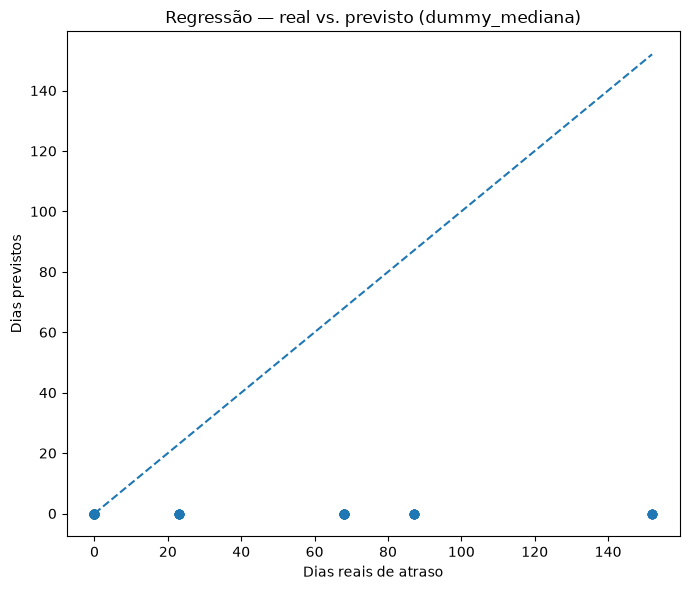

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(
    reg_test_eval["target_dias_atraso"],
    reg_test_eval["pred"],
    alpha=0.55,
)
mx = max(reg_test_eval["target_dias_atraso"].max(), reg_test_eval["pred"].max())
plt.plot([0, mx], [0, mx], linestyle="--")
plt.xlabel("Dias reais de atraso")
plt.ylabel("Dias previstos")
plt.title(f"Regressão — real vs. previsto ({best_reg_name})")
plt.tight_layout()
plt.show()


In [20]:
train_reg = reg_data[
    reg_data["split_modelagem"] == "train"
]

print(
    train_reg["target_dias_atraso"]
    .describe(percentiles=[.25, .5, .75, .9])
)

print(
    "\nPercentual de snapshots com target zero:",
    (train_reg["target_dias_atraso"] == 0).mean()
)

count   400.0000
mean     63.6300
std     104.1902
min       0.0000
25%       0.0000
50%      12.0000
75%      97.0000
90%     281.0000
max     380.0000
Name: target_dias_atraso, dtype: float64

Percentual de snapshots com target zero: 0.49


In [21]:
target_por_contrato = (
    train_reg
    .groupby("id_contrato")["target_dias_atraso"]
    .first()
)

print(target_por_contrato.describe())

print(
    "\nContratos sem atraso:",
    (target_por_contrato == 0).sum()
)

print(
    "Contratos com atraso:",
    (target_por_contrato > 0).sum()
)

print(
    "Mediana por contrato:",
    target_por_contrato.median()
)

count    36.0000
mean     40.8611
std      83.6572
min       0.0000
25%       0.0000
50%       0.0000
75%      30.0000
max     380.0000
Name: target_dias_atraso, dtype: float64

Contratos sem atraso: 19
Contratos com atraso: 17
Mediana por contrato: 0.0


In [22]:
target_por_contrato[
    target_por_contrato > 0
].describe()

count    17.0000
mean     86.5294
std     105.4070
min      12.0000
25%      25.0000
50%      30.0000
75%     106.0000
max     380.0000
Name: target_dias_atraso, dtype: float64

verificar as previsões antes do truncamento. No notebook, adicione:

In [23]:
pred_raw = fitted_regression["ridge"].predict(Xr_test)

print(pd.Series(pred_raw).describe())

print(
    "Percentual de previsões negativas:",
    (pred_raw < 0).mean()
)

print(
    "Percentual <= 0:",
    (pred_raw <= 0).mean()
)

count    149.0000
mean      38.1090
std       43.0922
min     -124.1329
25%       26.3887
50%       43.8060
75%       63.2041
max      124.4381
dtype: float64
Percentual de previsões negativas: 0.10067114093959731
Percentual <= 0: 0.10067114093959731


In [24]:
pd.DataFrame({
    "real": yr_test.values,
    "pred_raw": pred_raw,
    "pred_truncada": np.maximum(0, pred_raw)
}).head(30)

,real,pred_raw,pred_truncada
0,68.0000,65.1664,65.1664
1,68.0000,66.0698,66.0698
2,68.0000,10.0682,10.0682
3,68.0000,24.2527,24.2527
4,68.0000,31.3930,31.3930
5,68.0000,-98.2324,0.0000
6,68.0000,-87.5400,0.0000
7,68.0000,-124.1329,0.0000
8,68.0000,-110.0021,0.0000
9,68.0000,-102.0160,0.0000


Também vale medir por target:

In [26]:
diagnostico = pd.DataFrame({
    "target": yr_test.values,
    "pred_raw": pred_raw
})

diagnostico["grupo"] = np.where(
    diagnostico["target"] == 0,
    "sem_atraso",
    "com_atraso"
)

diagnostico.groupby("grupo")[["target", "pred_raw"]].agg(
    ["mean", "median", "min", "max"]
)

target                          pred_raw                    \
              mean  median     min      max     mean  median       min   
grupo                                                                    
com_atraso 74.7595 68.0000 23.0000 152.0000  27.0873 36.6396 -124.1329   
sem_atraso  0.0000  0.0000  0.0000   0.0000  50.5478 52.7078    4.6039   

                     
                max  
grupo                
com_atraso 124.4381  
sem_atraso 101.2177

Também é importante olhar a distribuição do treino:

In [27]:
train_targets = (
    reg_data[reg_data["split_modelagem"] == "train"]
    .groupby("id_contrato")["target_dias_atraso"]
    .first()
)

print(train_targets.describe())

print(
    "Percentual de contratos com target zero:",
    (train_targets == 0).mean()
)

count    36.0000
mean     40.8611
std      83.6572
min       0.0000
25%       0.0000
50%       0.0000
75%      30.0000
max     380.0000
Name: target_dias_atraso, dtype: float64
Percentual de contratos com target zero: 0.5277777777777778


# Parte B — Classificação baseline

A avaliação principal é feita **antes do vencimento do prazo**.

Modelos:

1. **Dummy prior:** reproduz a prevalência observada no treino.
2. **Regressão logística:** baseline probabilístico principal, sem rebalanceamento artificial das classes.
3. **Regressão logística balanceada:** referência adicional para verificar o efeito de priorizar separação entre classes.

A logística padrão é a principal referência de **probabilidade**, pois `class_weight="balanced"` altera o peso relativo das classes e pode degradar a calibração.

Métricas:
- balanced accuracy;
- precision, recall e F1;
- ROC-AUC;
- **PR-AUC / Average Precision**;
- **Brier Score**, especialmente importante porque a probabilidade prevista será utilizada operacionalmente.


In [10]:
clf_train, Xc_train, _, yc_train, wc_train = split_xy(clf_data, "train")
clf_val, Xc_val, _, yc_val, wc_val = split_xy(clf_data, "validation")
clf_test, Xc_test, _, yc_test, wc_test = split_xy(clf_data, "test")

classification_models = {
    "dummy_prior": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "regressao_logistica": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
    "regressao_logistica_balanceada": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
}


def classification_metrics(y_true, pred, proba, sample_weight=None):
    metrics = {
        "accuracy": accuracy_score(y_true, pred, sample_weight=sample_weight),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred, sample_weight=sample_weight),
        "precision": precision_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "recall": recall_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "f1": f1_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "brier": brier_score_loss(y_true, proba, sample_weight=sample_weight),
    }
    if pd.Series(y_true).nunique() == 2:
        metrics["roc_auc"] = roc_auc_score(y_true, proba, sample_weight=sample_weight)
        metrics["pr_auc"] = average_precision_score(y_true, proba, sample_weight=sample_weight)
    else:
        metrics["roc_auc"] = np.nan
        metrics["pr_auc"] = np.nan
    return metrics


classification_results = []
fitted_classification = {}

for name, model in classification_models.items():
    model.fit(Xc_train, yc_train, model__sample_weight=wc_train)
    fitted_classification[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xc_val, yc_val, wc_val),
        ("test", Xc_test, yc_test, wc_test),
    ]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= 0.50).astype(int)

        row = {"modelo": name, "split": split_name, "threshold": 0.50}
        row.update(classification_metrics(y_, pred, proba, w_))
        classification_results.append(row)

classification_metrics_df = pd.DataFrame(classification_results)
display(classification_metrics_df.sort_values(["split", "brier"], ascending=[True, True]))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
1,dummy_prior,test,0.5000,0.6447,0.5000,0.0000,0.0000,0.0000,0.2315,0.5000,0.3553
3,regressao_logistica,test,0.5000,0.5565,0.4446,0.1594,0.0581,0.0852,0.3453,0.2531,0.2919
5,regressao_logistica_balanceada,test,0.5000,0.3856,0.3562,0.2057,0.2549,0.2276,0.3811,0.2548,0.3080
0,dummy_prior,validation,0.5000,0.7267,0.5000,0.0000,0.0000,0.0000,0.2159,0.5000,0.2733
2,regressao_logistica,validation,0.5000,0.7267,0.5000,0.0000,0.0000,0.0000,0.2397,0.4512,0.2410
4,regressao_logistica_balanceada,validation,0.5000,0.4683,0.3591,0.1000,0.1182,0.1083,0.2527,0.4575,0.2428


## 5. Threshold escolhido na validação

A probabilidade prevista é a saída principal. O threshold serve apenas para converter risco em decisão binária.

O threshold é ajustado **somente na validação** usando a regressão logística padrão e depois congelado para o teste. Como referência simples, escolhemos o ponto que maximiza F1 ponderado por contrato.

> Em produção, o threshold deveria refletir o custo de falso positivo e falso negativo, e não apenas uma métrica estatística.


In [11]:
probability_model_name = "regressao_logistica"
logit = fitted_classification[probability_model_name]
val_proba = logit.predict_proba(Xc_val)[:, 1]

threshold_grid = np.arange(0.10, 0.91, 0.02)
threshold_rows = []

for threshold in threshold_grid:
    pred = (val_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "f1": f1_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(yc_val, pred, sample_weight=wc_val),
        "precision": precision_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
        "recall": recall_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_table.sort_values(["f1", "balanced_accuracy"], ascending=False).iloc[0]["threshold"]
)

print(f"Modelo probabilístico: {probability_model_name}")
print(f"Threshold escolhido na validação: {best_threshold:.2f}")
display(
    threshold_table.sort_values(["f1", "balanced_accuracy"], ascending=False).head(10)
)


Modelo probabilístico: regressao_logistica
Threshold escolhido na validação: 0.10


,threshold,f1,balanced_accuracy,precision,recall
0,0.1000,0.3498,0.4739,0.2557,0.5532
1,0.1200,0.3401,0.4660,0.2500,0.5319
2,0.1400,0.3401,0.4660,0.2500,0.5319
3,0.1600,0.3401,0.4660,0.2500,0.5319
4,0.1800,0.3401,0.4660,0.2500,0.5319
5,0.2000,0.3401,0.4660,0.2500,0.5319
6,0.2200,0.3401,0.4660,0.2500,0.5319
7,0.2400,0.3401,0.4660,0.2500,0.5319
8,0.2600,0.3401,0.4660,0.2500,0.5319
11,0.3200,0.3374,0.4864,0.2623,0.4728


In [12]:
test_proba = logit.predict_proba(Xc_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

final_classification_metrics = {
    "modelo": probability_model_name,
    "split": "test",
    "threshold": best_threshold,
    **classification_metrics(yc_test, test_pred, test_proba, wc_test),
}
display(pd.DataFrame([final_classification_metrics]))

classification_predictions = clf_test[
    ["id_contrato", "data_corte", "dias_restantes_prazo_vigente",
     "faixa_antecedencia", "target_atraso", "sample_weight_contrato"]
].copy()
classification_predictions["prob_atraso"] = test_proba
classification_predictions["pred_atraso"] = test_pred

display(classification_predictions.head(10))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,regressao_logistica,test,0.1000,0.1943,0.2735,0.2316,0.5470,0.3254,0.3453,0.2531,0.2919


,id_contrato,data_corte,dias_restantes_prazo_vigente,faixa_antecedencia,target_atraso,sample_weight_contrato,prob_atraso,pred_atraso
1056,217,2023-05-25,900,>=180d,1.0000,0.3365,0.0287,0
1057,217,2023-05-31,894,>=180d,1.0000,0.3365,0.0291,0
1058,217,2023-06-30,864,>=180d,1.0000,0.3365,0.0201,0
1059,217,2023-07-31,833,>=180d,1.0000,0.3365,0.0267,0
1060,217,2023-08-31,802,>=180d,1.0000,0.3365,0.0402,0
1061,217,2023-09-30,772,>=180d,1.0000,0.3365,0.0004,0
1062,217,2023-10-31,801,>=180d,1.0000,0.3365,0.0004,0
1063,217,2023-11-30,771,>=180d,1.0000,0.3365,0.0001,0
1064,217,2023-12-31,740,>=180d,1.0000,0.3365,0.0002,0
1065,217,2024-01-31,709,>=180d,1.0000,0.3365,0.0002,0


### Avaliação complementar por contrato em horizonte aproximadamente fixo

Métricas por snapshot ainda contêm várias observações da mesma obra. Como diagnóstico complementar, selecionamos **um snapshot por contrato**, o mais próximo de 90 dias antes do prazo vigente, e calculamos as métricas sem pesos.

In [13]:
contract_eval = classification_predictions.copy()
contract_eval["dist_90d"] = (
    contract_eval["dias_restantes_prazo_vigente"] - 90
).abs()

contract_eval = (
    contract_eval.sort_values(["id_contrato", "dist_90d", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .first()
)

if contract_eval["target_atraso"].nunique() == 2:
    contract_level_metrics = pd.DataFrame([{
        "horizonte_referencia_dias": 90,
        "contratos": len(contract_eval),
        **classification_metrics(
            contract_eval["target_atraso"].astype(int),
            contract_eval["pred_atraso"].astype(int),
            contract_eval["prob_atraso"],
            sample_weight=None,
        ),
    }])
else:
    contract_level_metrics = pd.DataFrame([{
        "horizonte_referencia_dias": 90,
        "contratos": len(contract_eval),
        "observacao": "Apenas uma classe presente neste recorte; AUC não calculável.",
    }])

display(contract_eval[
    ["id_contrato", "data_corte", "dias_restantes_prazo_vigente",
     "target_atraso", "prob_atraso", "pred_atraso"]
])
display(contract_level_metrics)


,id_contrato,data_corte,dias_restantes_prazo_vigente,target_atraso,prob_atraso,pred_atraso
0,217,2025-10-31,100,1.0000,0.0544,0
1,254,2025-05-31,83,0.0000,0.4157,1
2,283,2024-11-30,97,0.0000,0.4042,1
3,287,2025-03-31,84,0.0000,0.3921,1
4,317,2024-11-30,84,1.0000,0.6215,1
5,342,2025-07-18,60,0.0000,0.4136,1
6,375,2026-01-31,104,0.0000,0.4589,1
7,377,2025-04-29,90,1.0000,0.3995,1
8,381,2025-06-30,81,1.0000,0.4394,1


,horizonte_referencia_dias,contratos,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,90,9,0.3333,0.3750,0.3750,0.7500,0.5000,0.2871,0.5000,0.6349


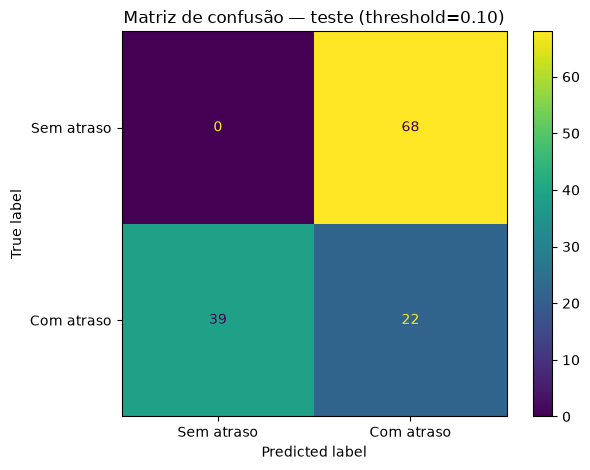

              precision    recall  f1-score   support

  Sem atraso       0.00      0.00      0.00        68
  Com atraso       0.24      0.36      0.29        61

    accuracy                           0.17       129
   macro avg       0.12      0.18      0.15       129
weighted avg       0.12      0.17      0.14       129



In [14]:
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    test_pred,
    display_labels=["Sem atraso", "Com atraso"],
    values_format="d",
)
plt.title(f"Matriz de confusão — teste (threshold={best_threshold:.2f})")
plt.tight_layout()
plt.show()

print(classification_report(
    yc_test,
    test_pred,
    target_names=["Sem atraso", "Com atraso"],
    zero_division=0,
))


## 6. Calibração das probabilidades

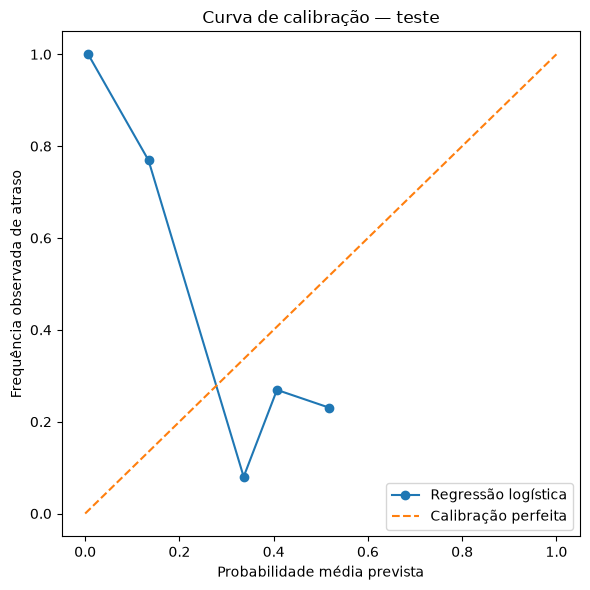

In [15]:
if pd.Series(yc_test).nunique() == 2:
    prob_true, prob_pred = calibration_curve(
        yc_test,
        test_proba,
        n_bins=5,
        strategy="quantile",
    )

    plt.figure(figsize=(6, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Regressão logística")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
    plt.xlabel("Probabilidade média prevista")
    plt.ylabel("Frequência observada de atraso")
    plt.title("Curva de calibração — teste")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 7. Coeficientes da regressão logística

Os coeficientes abaixo são da **regressão logística padrão**, usada como baseline probabilístico. Eles representam associações dentro do modelo linear, não efeitos causais. Como as features numéricas são padronizadas, a magnitude é aproximadamente comparável entre elas.


In [16]:
feature_names = logit.named_steps["preprocessing"].get_feature_names_out()
coefficients = logit.named_steps["model"].coef_[0]

coefficient_table = (
    pd.DataFrame({
        "caracteristica": feature_names,
        "coeficiente": coefficients,
        "efeito_absoluto": np.abs(coefficients),
    })
    .sort_values("efeito_absoluto", ascending=False)
)

display(coefficient_table.head(20))


,caracteristica,coeficiente,efeito_absoluto
0,numeric__valor_total_contrato,-1.5242,1.5242
7,numeric__qtd_aditivos_valor,0.9294,0.9294
9,numeric__atraso_medio_parcelas_dias,0.7238,0.7238
1,numeric__prazo_original_dias,0.6216,0.6216
2,numeric__dias_desde_os,0.5893,0.5893
10,numeric__atraso_maximo_parcelas_dias,-0.4302,0.4302
5,numeric__qtd_aditivos_prazo,-0.4289,0.4289
14,numeric__missingindicator_pct_parcelas_conclui...,-0.2325,0.2325
6,numeric__dias_aditados_acumulados,-0.1674,0.1674
15,numeric__missingindicator_atraso_medio_parcela...,0.1442,0.1442


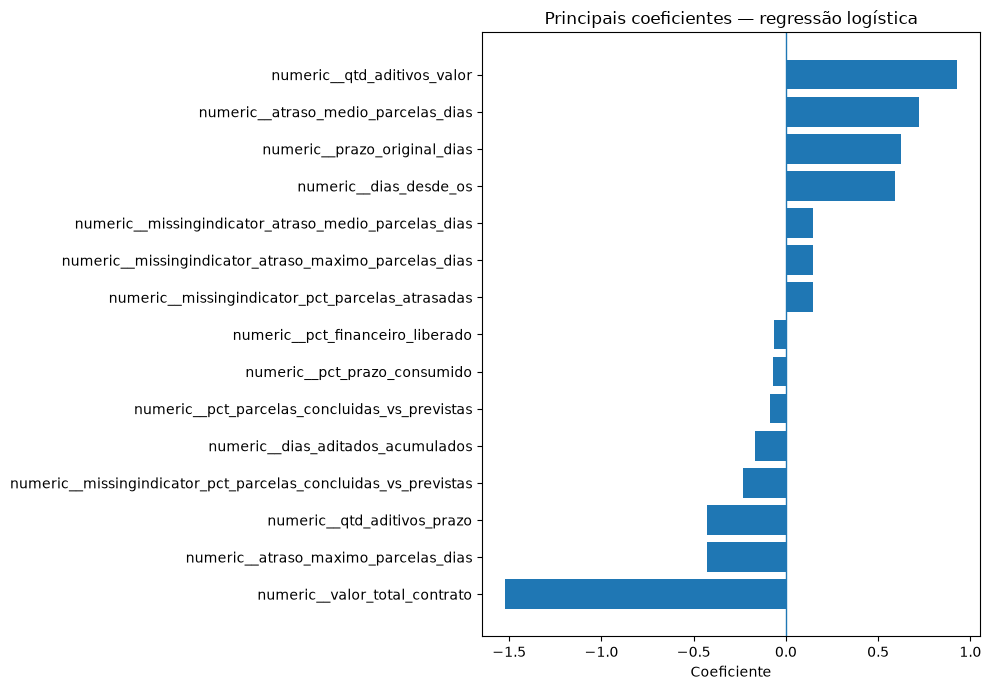

In [17]:
top = coefficient_table.head(15).sort_values("coeficiente")

plt.figure(figsize=(10, 7))
plt.barh(top["caracteristica"], top["coeficiente"])
plt.axvline(0, linewidth=1)
plt.title("Principais coeficientes — regressão logística")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()


## 8. Sanity checks contra leakage e contaminação entre splits

As verificações abaixo asseguram que:

- cada contrato rotulado pertence a apenas um split;
- o split é compatível com a nova conclusão definitiva;
- features proibidas não entram no modelo;
- `data_conclusao_definitiva` não entra em `X`;
- o conjunto principal de classificação não contém snapshots após o vencimento do prazo.


In [18]:
# Contratos não podem aparecer em mais de um split supervisionado.
contract_splits = (
    model_data.groupby("id_contrato")["split_modelagem"]
    .nunique()
)
assert contract_splits.max() == 1, "Há contratos em mais de um split."

forbidden = {
    "id_contrato",
    "numero_contrato",
    "status_final_controle",
    "data_conclusao_definitiva",
    "data_conclusao_controle",
    "data_conclusao_sistema_controle",
    "data_termino_vigente_final_controle",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "sample_weight_contrato",
    "sample_weight_contrato_raw",
    "split_modelagem",
    "split_contrato_temporal",
}

assert not (set(features) & forbidden), "Feature proibida encontrada em X."
assert clf_data["dias_restantes_prazo_vigente"].ge(0).all()

# Todo snapshot apto ao treino deve ocorrer antes da conclusão definitiva.
assert (
    model_data["data_corte"]
    < model_data["data_conclusao_definitiva"]
).all(), "Há snapshot supervisionado na ou após a conclusão definitiva."

# Revalida target binário.
target_bin_recalc = (model_data["target_dias_atraso"] > 0).astype(int)
assert (
    target_bin_recalc.values
    == model_data["target_atraso"].astype(int).values
).all(), "target_atraso inconsistente com target_dias_atraso."

print("Sanity checks concluídos com sucesso.")


Sanity checks concluídos com sucesso.


## 9. Salvamento de métricas, previsões e coeficientes

In [19]:
regression_metrics_df.to_csv(
    METRICS_DIR / "baseline_regressao_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_metrics_df.to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_threshold_050.csv",
    index=False,
    encoding="utf-8-sig",
)
pd.DataFrame([final_classification_metrics]).to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_teste_threshold_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)
threshold_table.to_csv(
    METRICS_DIR / "baseline_classificacao_thresholds_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)
horizon_metrics.to_csv(
    METRICS_DIR / "baseline_regressao_metricas_por_antecedencia.csv",
    index=False,
    encoding="utf-8-sig",
)
regression_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_regressao_previsoes_teste.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_classificacao_previsoes_teste.csv",
    index=False,
    encoding="utf-8-sig",
)
contract_level_metrics.to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_por_contrato_90d.csv",
    index=False,
    encoding="utf-8-sig",
)
coefficient_table.to_csv(
    METRICS_DIR / "baseline_regressao_logistica_coeficientes.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Métricas:", METRICS_DIR)
print("Previsões:", PREDICTIONS_DIR)


Métricas: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\metrics
Previsões: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\predictions
